# Práctica 5 - Análisis Exploratorio de Datos (EDA)

**Sesión 5 - Exploración de datos**    
**Herramientas:** Python, pandas y Matplotlib  
**Dataset:** `clientes_ecommerce.csv`

## Objetivos

En esta práctica aprenderás a:

- realizar un análisis exploratorio de un dataset
- estudiar distribuciones numéricas y categóricas
- interpretar media, mediana, cuartiles y desviación estándar
- utilizar histogramas, gráficos de barras, boxplots y diagramas de dispersión
- detectar posibles valores atípicos mediante el IQR
- estudiar relaciones entre variables
- calcular e interpretar correlaciones
- comparar grupos mediante `groupby()` y `crosstab()`
- diferenciar asociación y causalidad
- comunicar hallazgos respaldados por evidencia

> **Importante:** no basta con generar resultados o gráficos. Cada análisis debe ir acompañado de una **interpretación**

## Preparación

Coloca `clientes_ecommerce.csv` en la misma carpeta que este notebook.

Importa NumPy, pandas y Matplotlib y carga el dataset en un DataFrame llamado `df`

In [52]:
# TODO: importa numpy, pandas y matplotlib.pyplot
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# TODO: carga clientes_ecommerce.csv en un DataFrame llamado df
df = pd.read_csv('clientes_ecommerce.csv')

# Parte 1 - Inspección inicial

## Ejercicio 1

Realiza una inspección inicial:

1. Muestra las primeras 10 filas.
2. Consulta las dimensiones.
3. Muestra los nombres de las columnas.
4. Consulta los tipos de datos.
5. Utiliza `info()`.

In [53]:
# TODO: muestra las primeras 10 filas
df.head(10)

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
0,20001,67,102.0,9000.00,60.73,7,3,Móvil,Oeste,Oro,5,No
1,20002,28,93.0,35683.86,131.74,6,1,Móvil,Este,Bronce,2,No
2,20003,19,87.0,37152.19,55.33,8,1,Ordenador,Este,Plata,5,Sí
3,20004,55,79.0,40158.29,24.33,7,0,Ordenador,Norte,Bronce,4,Sí
4,20005,39,3.0,27317.06,88.78,5,0,Móvil,Sur,Bronce,4,No
5,20006,45,25.0,32627.01,59.77,9,2,Móvil,Este,Bronce,5,No
6,20007,22,105.0,44101.68,109.67,8,0,Móvil,Norte,Oro,5,Sí
7,20008,39,90.0,44882.10,57.56,7,2,Ordenador,Norte,Plata,2,Sí
8,20009,55,56.0,55299.19,49.94,6,2,Móvil,Sur,Bronce,5,No
9,20010,38,93.0,9000.00,110.69,10,2,Ordenador,Centro,Oro,4,Sí


In [54]:
# TODO: consulta las dimensiones
df.shape

(400, 12)

In [55]:
# TODO: muestra los nombres de las columnas
for c in df.columns:
    print(c)

cliente_id
edad
antiguedad_meses
ingresos_anuales
gasto_mensual
num_compras
devoluciones
dispositivo
zona
nivel_fidelidad
satisfaccion
compra_proximo_mes


In [56]:
# TODO: consulta los tipos de datos
for columna, tipo in df.dtypes.items():
    print(f"{columna}: {tipo}")

cliente_id: int64
edad: int64
antiguedad_meses: float64
ingresos_anuales: float64
gasto_mensual: float64
num_compras: int64
devoluciones: int64
dispositivo: str
zona: str
nivel_fidelidad: str
satisfaccion: int64
compra_proximo_mes: str


In [57]:
# TODO: utiliza info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   cliente_id          400 non-null    int64  
 1   edad                400 non-null    int64  
 2   antiguedad_meses    395 non-null    float64
 3   ingresos_anuales    396 non-null    float64
 4   gasto_mensual       397 non-null    float64
 5   num_compras         400 non-null    int64  
 6   devoluciones        400 non-null    int64  
 7   dispositivo         400 non-null    str    
 8   zona                400 non-null    str    
 9   nivel_fidelidad     400 non-null    str    
 10  satisfaccion        400 non-null    int64  
 11  compra_proximo_mes  400 non-null    str    
dtypes: float64(3), int64(5), str(4)
memory usage: 37.6 KB


### Responde

1. ¿Cuántas muestras contiene?
Contiene 400 muestras
2. ¿Cuántas columnas?
12 columnas
3. ¿Cuál es la unidad de observación?
El cliente
4. ¿Cuál es el identificador?
La columna `cliente_id`
5. ¿Cuál es el target?
La columna `compra_proximo_mes`
6. ¿Qué columnas tienen valores ausentes?
Las columnas que tienen valores ausentes o nulos son: 
- `antiguedad_meses`
- `ingresos_anuales`
- `gasto_mensual`

**Respuesta:**  
El dataset `clientes_ecommerce.csv` contiene 400 filas o muestras totales, con 12 columnas, de las cuales 10 son las características que puedo analizar. La unidad de observación es el cliente ya que cada fila recoge información de un cliente distinto. Las columnas que tienen valores ausentes son: `antiguedad_meses` con 5 nulos, `ingresos_anuales` con 4 nulos y `gasto_mensual` con 3 nulos.

# Parte 2 - Exploración de una variable numérica

Vamos a estudiar `gasto_mensual`.

## Ejercicio 2 - Estadística descriptiva

Obtén el número de valores, media, mediana, desviación estándar, mínimo, \(Q_1\), \(Q_2\), \(Q_3\) y máximo.

In [95]:
# TODO: muestra describe() para gasto_mensual
print(df['gasto_mensual'].describe())


# TODO: calcula las medidas necesarias
gasto = df["gasto_mensual"]
print(f"Número de valores totales: {gasto.count()}")
print(f"Media: {gasto.mean():.2f}")
print(f"Mediana: {gasto.median():.2f}")
print(f"Desviación estandar: {gasto.std():.2f}")
print(f"Valor mínimo: {gasto.min():.2f}")
print(f"Q1: {gasto.quantile(.25):.2f}")
print(f"Q2: {gasto.quantile(.5):.2f}")
print(f"Q3: {gasto.quantile(.75):.2f}")
print(f"Valor máximo: {gasto.max():.2f}")

count    397.000000
mean      69.089320
std       39.023238
min        5.770000
25%       39.720000
50%       61.170000
75%       90.150000
max      260.000000
Name: gasto_mensual, dtype: float64
Número de valores totales: 397
Media: 69.09
Mediana: 61.17
Desviación estandar: 39.02
Valor mínimo: 5.77
Q1: 39.72
Q2: 61.17
Q3: 90.15
Valor máximo: 260.00


### Completa

| Medida | Valor |
|---|---:|
| Número de valores | 397 |
| Media | 69.09 |
| Mediana | 61.17 |
| Desviación estándar | 39.02 |
| Mínimo | 5.77 |
| Q1 | 39.7 |
| Q2 | 61.17 |
| Q3 | 90.15 |
| Máximo | 260 |

### Interpreta

1. ¿Coinciden exactamente media y mediana?
No coinciden exactamente
2. ¿Cuál es mayor?
La media
3. ¿Qué puede indicar esta diferencia sobre la distribución?
La cantidad de valores se centra en valores bajos
4. ¿Entre qué valores se encuentra aproximadamente el 50 % central?
Aproximadamente el 50% se encuentra entre los valores 39.7 y 90.15

**Respuesta:**  
Con los valores que me da `describe()`, la media y la mediana no coinciden ya que la media es mayor a la mediana. Esto me indica que al crear los diagramas los valores del dataset se concentrarán en valores bajos y eso conlleva a que se forme una cola de valores más grandes y atípicos hacia la derecha. También me indica que el 50% se encontraría entre los valores 39.72 y 90.15 en los diagramas.

# Parte 3 - Visualizar la distribución

## Ejercicio 3 - Histograma

Crea un histograma de `gasto_mensual` utilizando aproximadamente `bins=15`.

Añade título y etiquetas en ambos ejes.

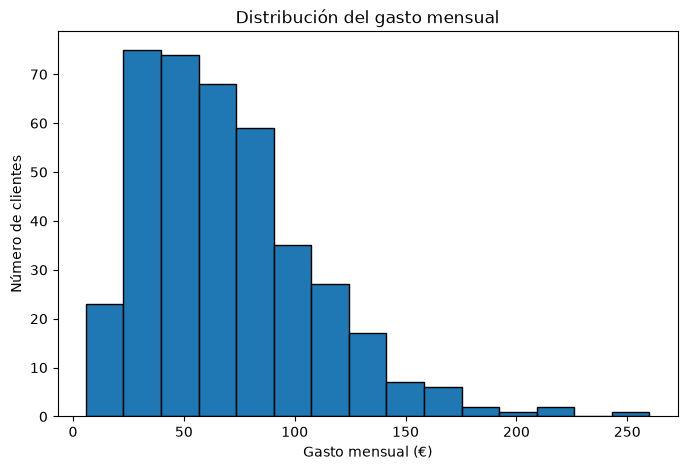

In [98]:
# TODO: crea el histograma de gasto_mensual
plt.figure(figsize=(8, 5))
plt.hist(df['gasto_mensual'].dropna(), bins=15, edgecolor="black")
plt.xlabel("Gasto mensual (€)")
plt.ylabel("Número de clientes")
plt.title("Distribución del gasto mensual")
plt.show()

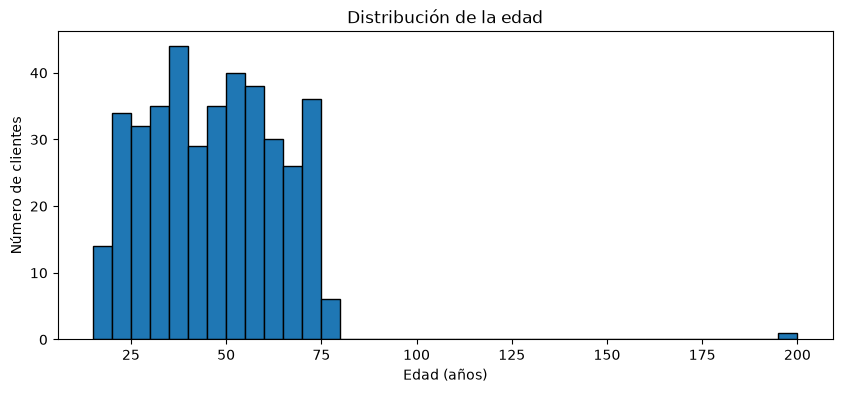

In [60]:
# Histograma de edad
plt.figure(figsize=(10, 4))
plt.hist(df["edad"], bins=range(15, 201, 5), edgecolor="black")
plt.title("Distribución de la edad")
plt.xlabel("Edad (años)")
plt.ylabel("Número de clientes")
plt.show()

### Interpreta

1. ¿Dónde parece concentrarse la mayoría de los clientes?
Se concentran aproximadamente entre los valores 25 y 115.
2. ¿La distribución parece aproximadamente simétrica?
No. Si se pliega por el valor central no es simétrica.
3. ¿Existe una cola hacia valores altos o bajos?
Sí, existe una cola hacia valores altos
4. ¿Observas valores alejados del resto?
Sí, hay un valor que está entre 243 y 260, es un valor atípico

**Respuesta:**  
El histograma afirma lo que decía de la media (69,09 €) que fuese mayor que la mediana (61,17 €), es decir la mayoría de los clientes gasta entre 23 € y 90 € al mes, la distribución del histograma no es simétrica y forma una cola hacia la derecha con unos pocos clientes con gastos mensuales elevados, y algunos muy alejados del resto de valores.

# Parte 4 - Boxplot y valores atípicos

## Ejercicio 4

Representa `gasto_mensual` mediante un boxplot. Trata adecuadamente los valores ausentes.

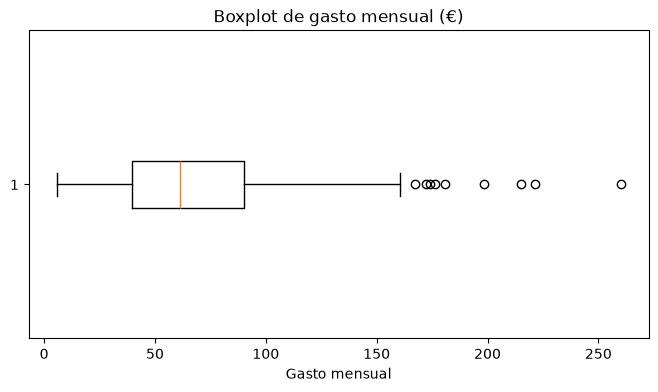

In [99]:
# TODO: crea un boxplot de gasto_mensual
plt.figure(figsize=(8, 4))
caja = plt.boxplot(df['gasto_mensual'].dropna(), orientation="horizontal")
plt.xlabel("Gasto mensual")
plt.title("Boxplot de gasto mensual (€)")
plt.show()

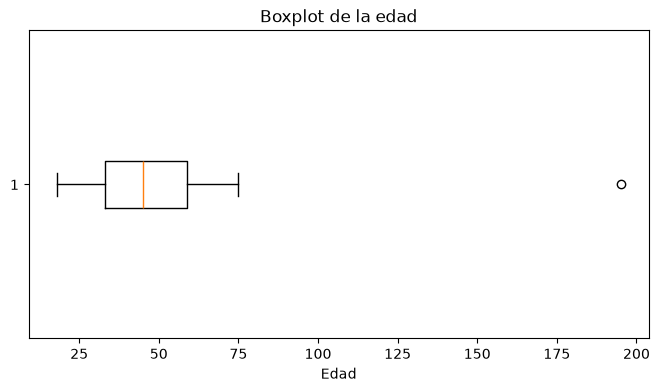

In [62]:
plt.figure(figsize=(8, 4))
plt.boxplot(df['edad'], orientation="horizontal")
plt.xlabel("Edad")
plt.title("Boxplot de la edad")
plt.show()

### Interpreta

1. ¿Dónde se encuentra aproximadamente la mediana?
Se encuentra entre los valores 39.72€ y 90.15€
2. ¿Observas posibles outliers?
Sí, 9 valores atípicos
3. ¿Aparecen principalmente por encima o por debajo?
Aparecen por encima, en los valores más altos
4. ¿Podemos afirmar que esos valores son errores únicamente observando el boxplot? Justifica.
No lo puedo afirmar porque puede ser que los valores porque, aunque puedan ser errores en algunos diagramas, también pueden ser correctos

**Respuesta:**  
La mediana en el boxplot se encuentra entre 61€, pero como hay una cola hacia la derecha hay 9 outliers que en este caso aparecen por encima, son los valores más altos, pero no se puede confirmar que sean errores porque pueden haber clientes que paguen entre 240€ y 260€ mensualmente

# Parte 5 - Detectar outliers mediante IQR

## Ejercicio 5

Calcula:

$$
IQR=Q_3-Q_1
$$

y:

$$
L_{inferior}=Q_1-1.5IQR
$$

$$
L_{superior}=Q_3+1.5IQR
$$

Después localiza los clientes cuyo `gasto_mensual` esté fuera de estos límites y guarda el resultado en `outliers_gasto`.

In [63]:
# TODO: calcula Q1, Q3 e IQR
Q1 = df['gasto_mensual'].quantile(.25)
Q2 = df['gasto_mensual'].quantile(.5)
Q3 = df['gasto_mensual'].quantile(.75)

# rango interquantilico
IQR = Q3 - Q1

# TODO: calcula los límites inferior y superior
l_inf_gasto = Q1 - (1.5 * IQR)
l_sup_gasto = Q3 + (1.5 * IQR)

# TODO: muestra los resultados
print(f"Rango interquantilico: {IQR:.2f}\nLímite inferior: {l_inf_gasto:.2f}\nLímite superior: {l_sup_gasto:.2f}")

Rango interquantilico: 50.43
Límite inferior: -35.93
Límite superior: 165.80


In [64]:
# TODO: calcula Q1, Q3 e IQR
Q1_edad = df['edad'].quantile(.25)
Q2_edad = df['edad'].quantile(.5)
Q3_edad = df['edad'].quantile(.75)

# rango interquantilico
IQR_edad = Q3_edad - Q1_edad

# TODO: calcula los límites inferior y superior
l_inf_edad = Q1_edad - (1.5 * IQR_edad)
l_sup_edad = Q3_edad + (1.5 * IQR_edad)

# TODO: muestra los resultados
print(f"Rango intercuartilico: {IQR_edad:.2f}\nLímite inferior: {l_inf_edad:.2f}\nLímite superior: {l_sup_edad:.2f}")

Rango intercuartilico: 26.00
Límite inferior: -6.00
Límite superior: 98.00


In [65]:
# TODO: crea outliers_gasto
filtro_outliers_gasto = (df['gasto_mensual'] < l_inf_gasto) | (df['gasto_mensual'] > l_sup_gasto)
outliers_gasto = df[filtro_outliers_gasto]

# TODO: muestra los posibles outliers
outliers_gasto

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
50,20051,75,49.0,22908.36,176.52,3,1,Móvil,Este,Oro,3,Sí
68,20069,29,78.0,33382.86,215.30,8,2,Móvil,Centro,Bronce,4,No
202,20203,45,57.0,24727.71,167.26,7,4,Móvil,Norte,Platino,1,Sí
203,20204,25,41.0,39329.38,173.91,6,0,Ordenador,Norte,Bronce,2,Sí
207,20208,41,65.0,25812.18,221.59,10,0,Ordenador,Centro,Plata,5,Sí
268,20269,21,61.0,34737.20,198.28,7,2,Tablet,Centro,Bronce,3,Sí
292,20293,20,94.0,31714.55,172.31,13,0,Tablet,Este,Bronce,3,Sí
318,20319,56,38.0,9000.00,180.60,4,0,Ordenador,Este,Bronce,2,Sí
398,20399,75,85.0,40391.73,260.00,10,1,Móvil,Oeste,Bronce,4,Sí


In [66]:
# TODO: crea outliers_edad
filtro_outliers_edad = (df['edad'] < l_inf_edad) | (df['edad'] > l_sup_edad)
outliers_edad = df[filtro_outliers_edad]

# TODO: muestra los posibles outliers
outliers_edad

,cliente_id,edad,antiguedad_meses,ingresos_anuales,gasto_mensual,num_compras,devoluciones,dispositivo,zona,nivel_fidelidad,satisfaccion,compra_proximo_mes
137,20138,195,106.0,32593.41,138.99,6,0,Móvil,Este,Plata,3,No


### Responde

1. ¿Cuántos posibles outliers has encontrado?
He encontrado 9 posibles outliers, todos ellos por encima del límite superior.
2. ¿Qué porcentaje representan?
Representan un 2% de los clientes.
3. ¿Cuál es el mayor `gasto_mensual`?
El mayor gasto mensual es de 260€
4. ¿Eliminarías automáticamente estas observaciones?
No. Puede que no sea un error superar el límite de IQR.
5. ¿Qué investigarías antes?
Si el resto de los datos del clientes hacen que ese gasto tenga credibilidad.

**Respuesta:**  
Los outliers encontrados son 9, todos por encima del límite superior del IQR, que representan el 2% de los clientes. El mayor gasto de todos los clientes es de 260€ al mes. Yo no eliminaría las observaciones que se salgan de lo normal del histograma ni observando el boxplot ya que pueden no ser errores. Como investigación extra, podría revisar si el resto de los datos del cliente hacen que el gasto de 180.60€ al mes es creible.

# Parte 6 - Comparar varias distribuciones

## Ejercicio 6

Analiza:

- `edad`
- `ingresos_anuales`
- `gasto_mensual`
- `num_compras`
- `devoluciones`

Consulta sus estadísticas descriptivas y crea un histograma independiente para cada variable.

In [101]:
# TODO: consulta las estadísticas descriptivas de las variables indicadas
variables = ["edad", "ingresos_anuales", "gasto_mensual", "num_compras", "devoluciones"]
df[variables].describe().round(2)

,edad,ingresos_anuales,gasto_mensual,num_compras,devoluciones
count,400.00,396.00,397.00,400.00,400.00
mean,46.40,36440.92,69.09,8.22,1.23
std,18.01,14325.23,39.02,2.78,1.14
min,18.00,9000.00,5.77,2.00,0.00
25%,33.00,26034.09,39.72,6.00,0.00
50%,45.00,36817.27,61.17,8.00,1.00
75%,59.00,45969.03,90.15,10.00,2.00
max,195.00,82925.37,260.00,17.00,5.00


In [109]:
# TODO: calcula sus medianas
print(f"Medianas:\n{df[variables].median().round(2)}")

Medianas:
edad                   45.00
ingresos_anuales    36817.27
gasto_mensual          61.17
num_compras             8.00
devoluciones            1.00
dtype: float64


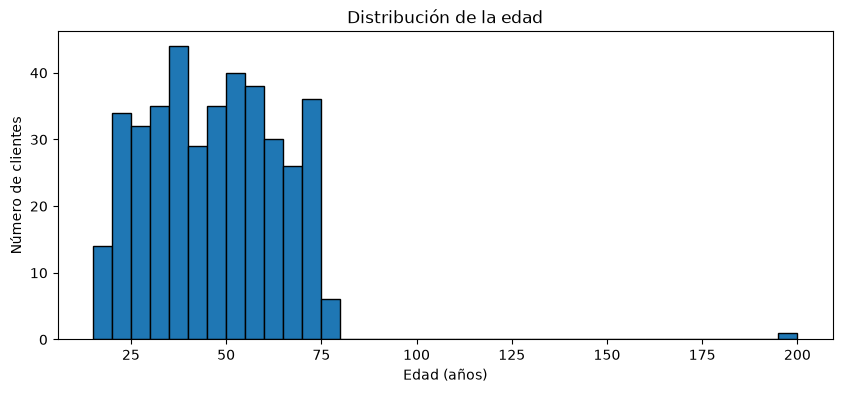

In [110]:
# TODO: histograma de edad
plt.figure(figsize=(10, 4))
plt.hist(df["edad"], bins=range(15, 201, 5), edgecolor="black")
plt.title("Distribución de la edad")
plt.xlabel("Edad (años)")
plt.ylabel("Número de clientes")
plt.show()

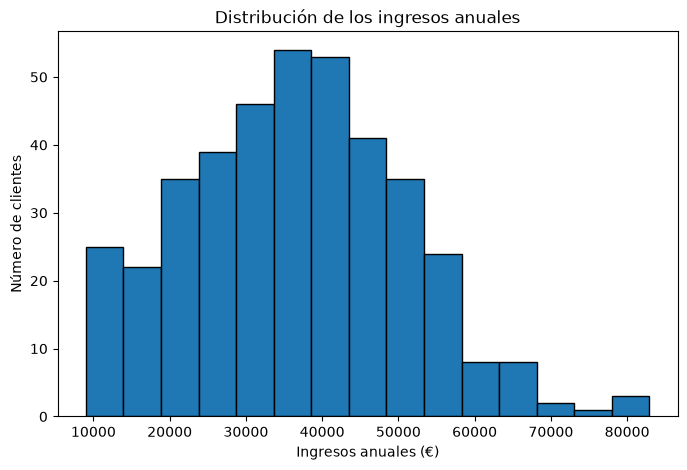

In [111]:
# TODO: histograma de ingresos_anuales
plt.figure(figsize=(8, 5))
plt.hist(df["ingresos_anuales"].dropna(), bins=15, edgecolor="black")
plt.title("Distribución de los ingresos anuales")
plt.xlabel("Ingresos anuales (€)")
plt.ylabel("Número de clientes")
plt.show()

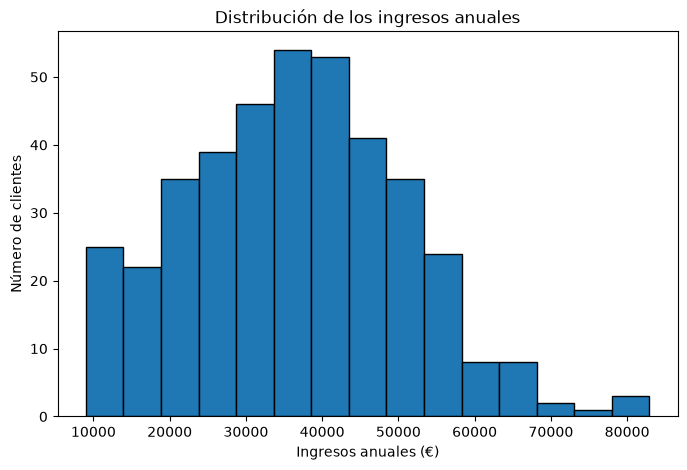

In [112]:
# TODO: histograma de gasto_mensual
plt.figure(figsize=(8, 5))
plt.hist(df["ingresos_anuales"].dropna(), bins=15, edgecolor="black")
plt.title("Distribución de los ingresos anuales")
plt.xlabel("Ingresos anuales (€)")
plt.ylabel("Número de clientes")
plt.show()

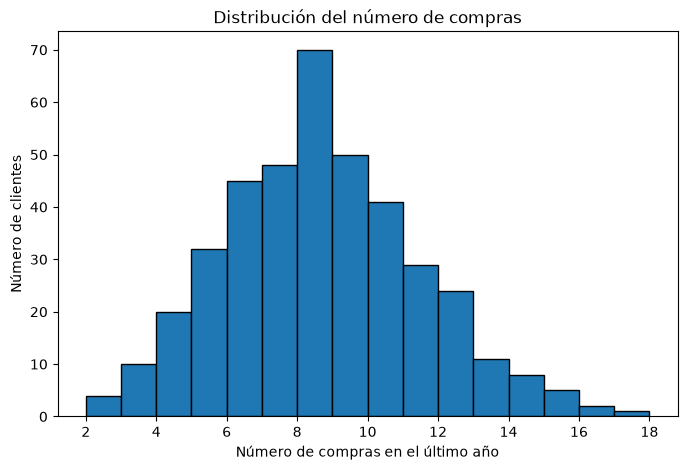

In [113]:
# TODO: histograma de num_compras
plt.figure(figsize=(8, 5))
plt.hist(df["num_compras"], bins=range(2, 19), edgecolor="black")
plt.title("Distribución del número de compras")
plt.xlabel("Número de compras en el último año")
plt.ylabel("Número de clientes")
plt.show()

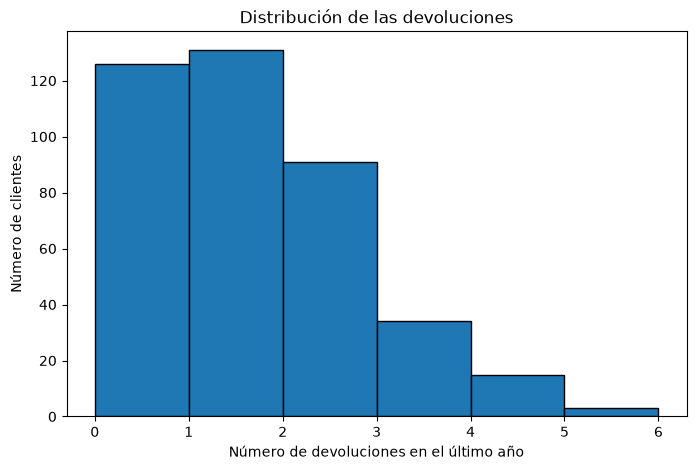

In [114]:
# TODO: histograma de devoluciones
plt.figure(figsize=(8, 5))
plt.hist(df["devoluciones"], bins=range(0, 7), edgecolor="black")
plt.title("Distribución de las devoluciones")
plt.xlabel("Número de devoluciones en el último año")
plt.ylabel("Número de clientes")
plt.show()

### Completa

| Variable | Media | Mediana | Mínimo | Máximo | Observación relevante |
|---|---:|---:|---:|---:|---|
| edad | 46.40 | 45 | 18 | 195 | Un cliente con 195 años es un valor imposible |
| ingresos_anuales | 36.440,92 | 36.817.27 | 9.000 | 82.925.37 | 16 clientes con 4 valores ausentes |
| gasto_mensual | 69.09 | 61.17 | 5.77 | 260 | Asimetría en la derecha, consiguiendo 9 posibles outliers |
| num_compras | 8.22 | 8 | 2 | 17 | Aproximadamente simétrica |
| devoluciones | 1.23 | 1 | 0 | 5 | La mayoría tiene 0 o 1 devoluciones, consiguiendo una cola hacia la derecha |

### Busca una observación sospechosa

- ¿Qué variable es?
`edad`.
- ¿Qué valor tiene?
195 años.
- ¿Por qué parece sospechoso?
Es sospechoso, y además biológicamente imposible. Nadie supera los 123 años.
- ¿Es un outlier?
Sí. Supera por mucho el límite superior del IQR.
- ¿Podemos afirmar directamente que es un error?
Casi con seguridad es un fallo de registro en el dataset. También podría ser un fallo al teclear el número.
- ¿Qué harías antes de modificarlo?
Lo primero: revisar el resto de datos de ese cliente, luego consultar en la fuente original de datos

**Respuesta:**  
Las cinco variables tienen comportamientos distintos. `num_compras`es aproximadamente simétrica, mientras que `gasto_mensual`y `devoluciones` presentan una cola hacia la derecha, con la media por encima de la mediana. Por otro lado `ingresos_anuales` tiene la media y la mediana muy próximas, pero muestra 16 clientes con exactamente 9.000€, un valor repetido que parece un valor de tope. La observación más sospechosa es un cliente con 195 años en `edad`, es decir, es un outlier según el IQR y, además, un valor imposible, casi con seguridad es un error de escritura.

# Parte 7 - Variables categóricas

## Ejercicio 7 - Frecuencias

Analiza `dispositivo`, `zona`, `nivel_fidelidad` y `compra_proximo_mes`.

Calcula frecuencias absolutas, relativas y porcentajes mediante `value_counts()`.

In [121]:
# TODO: analiza dispositivo
print("Frecuencia absoluta:")
print(df["dispositivo"].value_counts())
print("\n")
print("Frecuencia relativa:")
print(df["dispositivo"].value_counts(normalize=True))
print("\n")
print("Porcentaje:")
print(df["dispositivo"].value_counts(normalize=True) * 100)

Frecuencia absoluta:
dispositivo
Móvil        242
Ordenador    133
Tablet        25
Name: count, dtype: int64


Frecuencia relativa:
dispositivo
Móvil        0.6050
Ordenador    0.3325
Tablet       0.0625
Name: proportion, dtype: float64


Porcentaje:
dispositivo
Móvil        60.50
Ordenador    33.25
Tablet        6.25
Name: proportion, dtype: float64


In [122]:
# TODO: analiza zona
print("Frecuencia absoluta:")
print(df["zona"].value_counts())
print("\n")
print("Frecuencia relativa:")
print(df["zona"].value_counts(normalize=True))
print("\n")
print("Porcentaje:")
print(df["zona"].value_counts(normalize=True) * 100)

Frecuencia absoluta:
zona
Este      89
Sur       80
Norte     79
Oeste     76
Centro    76
Name: count, dtype: int64


Frecuencia relativa:
zona
Este      0.2225
Sur       0.2000
Norte     0.1975
Oeste     0.1900
Centro    0.1900
Name: proportion, dtype: float64


Porcentaje:
zona
Este      22.25
Sur       20.00
Norte     19.75
Oeste     19.00
Centro    19.00
Name: proportion, dtype: float64


In [123]:
# TODO: analiza nivel_fidelidad
print("Frecuencia absoluta:")
print(df["nivel_fidelidad"].value_counts())
print("\n")
print("Frecuencia relativa:")
print(df["nivel_fidelidad"].value_counts(normalize=True))
print("\n")
print("Porcentaje:")
print(df["nivel_fidelidad"].value_counts(normalize=True) * 100)

Frecuencia absoluta:
nivel_fidelidad
Bronce     162
Plata      105
Oro         83
Platino     50
Name: count, dtype: int64


Frecuencia relativa:
nivel_fidelidad
Bronce     0.4050
Plata      0.2625
Oro        0.2075
Platino    0.1250
Name: proportion, dtype: float64


Porcentaje:
nivel_fidelidad
Bronce     40.50
Plata      26.25
Oro        20.75
Platino    12.50
Name: proportion, dtype: float64


In [124]:
# TODO: analiza compra_proximo_mes
print("Frecuencia absoluta:")
print(df["compra_proximo_mes"].value_counts())
print("\n")
print("Frecuencia relativa:")
print(df["compra_proximo_mes"].value_counts(normalize=True))
print("\n")
print("Porcentaje:")
print(df["compra_proximo_mes"].value_counts(normalize=True) * 100)

Frecuencia absoluta:
compra_proximo_mes
No    246
Sí    154
Name: count, dtype: int64


Frecuencia relativa:
compra_proximo_mes
No    0.615
Sí    0.385
Name: proportion, dtype: float64


Porcentaje:
compra_proximo_mes
No    61.5
Sí    38.5
Name: proportion, dtype: float64


### Completa

| Variable | Categoría más frecuente | Nº muestras | Porcentaje |
|---|---|---:|---:|
| dispositivo | Móvil | 242 | 60.50% |
| zona | Este | 89 | 22.25% |
| nivel_fidelidad | Bronce | 162 | 40.50% |
| compra_proximo_mes | No | 246 | 61.50% |

# Parte 8 - Visualización de variables categóricas

## Ejercicio 8

Crea gráficos de barras independientes para:

- `dispositivo`
- `nivel_fidelidad`
- `compra_proximo_mes`

Todos deben incluir título y etiquetas.

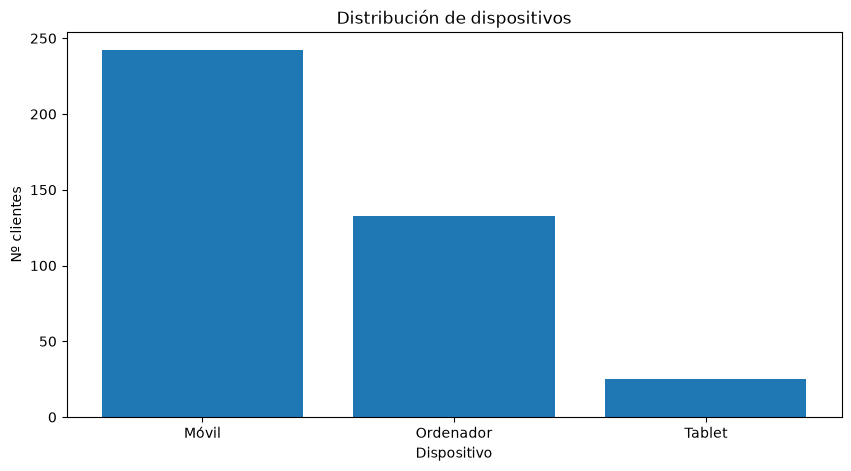

In [78]:
# TODO: gráfico de barras de dispositivo
conteos_disp = df["dispositivo"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(conteos_disp.index, conteos_disp.values)
plt.xlabel("Dispositivo")
plt.ylabel("Nº clientes")
plt.title("Distribución de dispositivos")
plt.show()

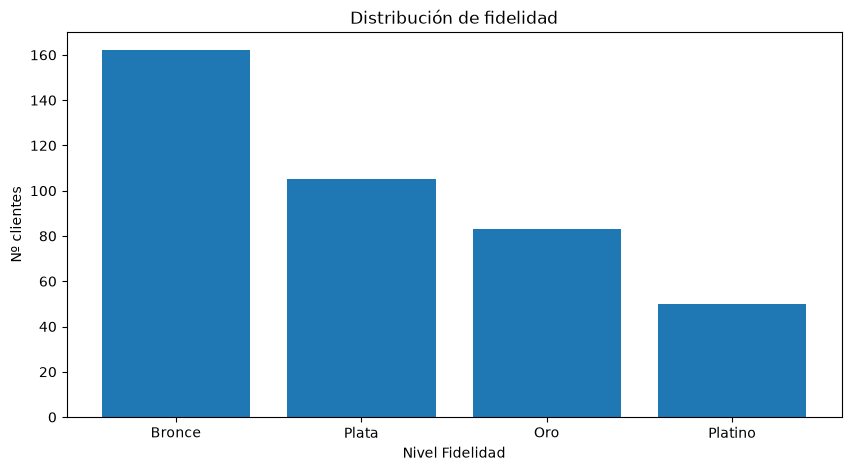

In [ ]:
# TODO: gráfico de barras de nivel_fidelidad
conteos_fid = df["nivel_fidelidad"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(conteos_fid.index, conteos_fid.values)
plt.xlabel("Nivel Fidelidad")
plt.ylabel("Nº clientes")
plt.title("Distribución de fidelidad")
plt.show()

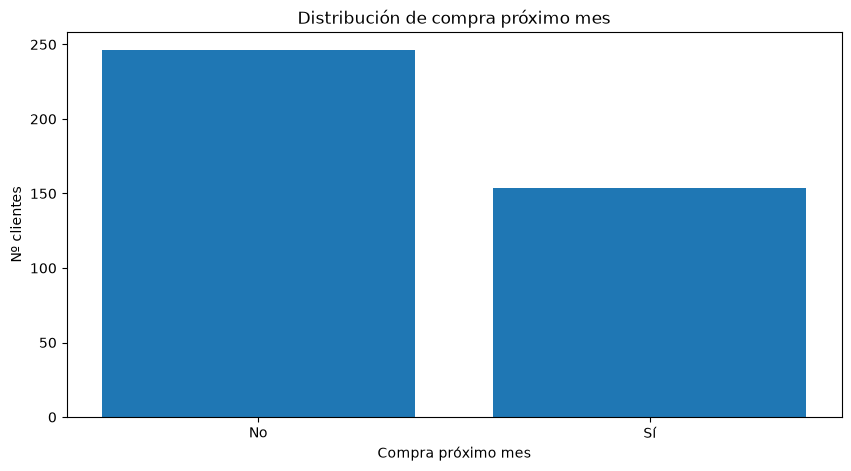

In [80]:
# TODO: gráfico de barras de compra_proximo_mes
conteos_compra = df["compra_proximo_mes"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(conteos_compra.index, conteos_compra.values)
plt.xlabel("Compra próximo mes")
plt.ylabel("Nº clientes")
plt.title("Distribución de compra próximo mes")
plt.show()

### Interpreta

Escribe al menos una conclusión sobre cada gráfico.

Para `compra_proximo_mes`, responde además:

> ¿Las clases están perfectamente equilibradas?

Justifica utilizando porcentajes.

**Respuesta:**  
- Dispositivo: el móvil domina claramente con un 60.50%, seguido del ordenador con un 33.25%, por último la tablet que no se vende mucho, con un 6.25%.
- Nivel de fidelidad: el número de clientes disminuye al subir de nivel, desde Bronce con un 40.50% de clientes hasta Platino con un 12.5% de clientes. Es lo esperable si los niveles altos son más dificiles de alcanzar.
- Compra del próximo mes: hay más clientes que no compran, un 61.5%, que los que sí compran, que representan el 38.5% del dataset.

¿Las clases están perfectamente equilibradas?
No. La clase "No" representa el 61.5% y la clase "Sí" el 38.5%, una diferencia de 23 puntos porcentuales.

# Parte 9 - Relación entre dos variables numéricas

Queremos investigar:

> **¿Existe alguna relación entre el número de compras realizadas y el gasto mensual?**

## Ejercicio 9 - Scatter plot

Representa:

$$
X=\text{num\_compras}
$$

$$
Y=\text{gasto\_mensual}
$$

mediante un diagrama de dispersión.

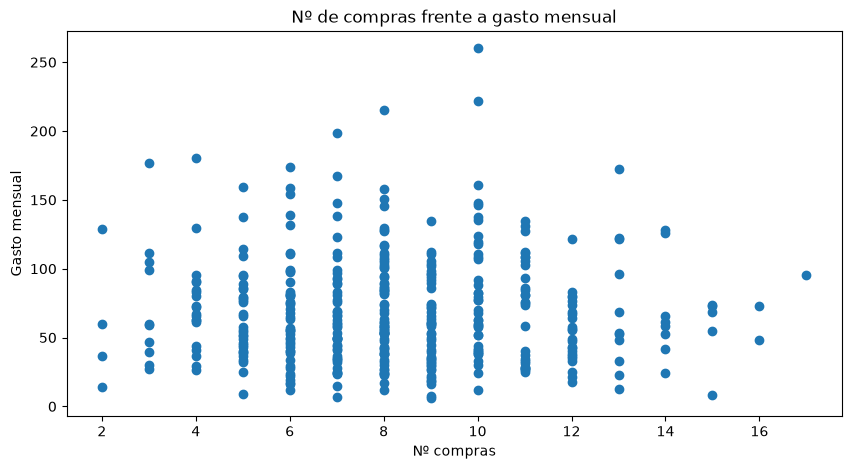

In [81]:
# TODO: crea un scatter plot de num_compras frente a gasto_mensual
conteos_compra = df["compra_proximo_mes"].value_counts()

plt.figure(figsize=(10, 5))
plt.scatter(df["num_compras"], df["gasto_mensual"])
plt.xlabel("Nº compras")
plt.ylabel("Gasto mensual")
plt.title("Nº de compras frente a gasto mensual")
plt.show()

### Antes de calcular la correlación

1. ¿Parece existir una relación?
2. ¿Parece positiva o negativa?
3. ¿Parece fuerte o débil?
4. ¿Observas muestras especialmente alejadas?

**Respuesta:**  
Escribe aquí.

# Parte 10 - Correlación

## Ejercicio 10

Calcula la correlación entre `num_compras` y `gasto_mensual` utilizando `corr()`.

In [82]:
# TODO: calcula la correlación entre num_compras y gasto_mensual
correlacion_num_compras_gasto_mes = df["num_compras"].corr(df["gasto_mensual"])
print(f"Correlación num_compras y gasto_mensual: {correlacion_num_compras_gasto_mes}")

# Próximo a 0 - No hay correlación
# Próximo a -1 - Hay correlación negativa
# Próximo a 1 - Hay correlación positiva

Correlación num_compras y gasto_mensual: -0.014165499001183279


### Interpreta

1. ¿Cuál es el valor de \(r\)?
2. ¿Es positivo o negativo?
3. ¿Qué significa el signo?
4. ¿Coincide con lo observado en el scatter plot?
5. ¿Podemos afirmar que realizar más compras **provoca** un mayor gasto mensual? Justifica.

**Respuesta:**  
Escribe aquí.

# Parte 11 - Matriz de correlaciones

## Ejercicio 11

Selecciona las variables numéricas y calcula su matriz de correlaciones.

> **Atención:** `cliente_id` es técnicamente numérico, pero conceptualmente es un identificador. No debes incluirlo.

In [83]:
# TODO: selecciona las variables numéricas excluyendo cliente_id
columnas_numericas = df.select_dtypes(include="number").drop(columns=["cliente_id"])
print(f"Columnas numéricas: {columnas_numericas}")

# TODO: calcula y muestra la matriz de correlaciones

Columnas numéricas:      edad  antiguedad_meses  ingresos_anuales  gasto_mensual  num_compras  \
0      67             102.0           9000.00          60.73            7   
1      28              93.0          35683.86         131.74            6   
2      19              87.0          37152.19          55.33            8   
3      55              79.0          40158.29          24.33            7   
4      39               3.0          27317.06          88.78            5   
..    ...               ...               ...            ...          ...   
395    28             100.0          27162.19          19.48            6   
396    67              67.0          36715.09          98.96            3   
397    34              75.0          32803.59          48.39           16   
398    75              85.0          40391.73         260.00           10   
399    38              73.0          27118.82          37.70           12   

     devoluciones  satisfaccion  
0               3    

### Interpreta

1. ¿Por qué todos los valores de la diagonal son 1?
2. ¿Por qué la matriz es simétrica?
3. Sin considerar la diagonal, ¿qué pareja presenta la correlación positiva más alta?
4. ¿Qué pareja presenta la correlación más negativa?
5. ¿Hay variables cuya correlación sea prácticamente cero?

**Respuesta:**  
Escribe aquí.

# Parte 12 - Visualizar las correlaciones

## Ejercicio 12

Representa la matriz mediante `plt.imshow()`.

Añade nombres de variables en ambos ejes, barra de color y título.

In [84]:
# TODO: representa la matriz de correlaciones con plt.imshow()

### Interpreta tres relaciones

Selecciona tres relaciones de la matriz y explica qué significa cada valor.

1. 
2. 
3. 

Recuerda:

$$
\boxed{\text{correlación}\neq\text{causalidad}}
$$

# Parte 13 - Variable numérica frente a categórica

Queremos investigar:

> **¿Los clientes que realizan una compra el mes siguiente presentan un gasto histórico diferente?**

## Ejercicio 13

Utiliza `groupby()` para obtener para cada valor de `compra_proximo_mes`:

- número de clientes
- gasto medio
- mediana
- desviación estándar.

In [85]:
# TODO: agrupa por compra_proximo_mes y calcula las estadísticas solicitadas

### Interpreta

1. ¿Qué grupo presenta mayor gasto medio?
2. ¿Y mayor mediana?
3. ¿Las diferencias parecen grandes o pequeñas?
4. ¿La media y la mediana cuentan exactamente la misma historia?

**Respuesta:**  
Escribe aquí.

# Parte 14 - Comparación visual entre grupos

## Ejercicio 14

Crea:

- `grupo_no`: gasto mensual de quienes no compran el mes siguiente
- `grupo_si`: gasto mensual de quienes sí compran.

Representa ambos mediante un único boxplot.

In [86]:
# TODO: crea grupo_no y grupo_si


# TODO: representa ambos grupos mediante un boxplot

### Interpreta

1. ¿Qué grupo presenta una mediana mayor?
2. ¿Cuál parece tener mayor dispersión?
3. ¿Existen outliers en ambos?
4. ¿El gráfico apoya las conclusiones obtenidas mediante `groupby()`?

**Respuesta:**  
Escribe aquí.

# Parte 15 - Dos variables categóricas

Queremos responder:

> **¿La proporción de compra es igual para todos los niveles de fidelidad?**

## Ejercicio 15

Crea:

1. una tabla de contingencia con frecuencias absolutas
2. una tabla normalizada por filas mediante `normalize="index"`
3. una versión expresada en porcentajes.

In [87]:
# TODO: tabla de contingencia con frecuencias absolutas

In [88]:
# TODO: tabla normalizada por filas

In [89]:
# TODO: muestra las proporciones como porcentajes

### Interpreta

1. ¿Qué nivel tiene mayor número absoluto de clientes que compran?
2. ¿Qué nivel tiene mayor porcentaje de clientes que compran?
3. ¿Coinciden necesariamente ambas respuestas?
4. ¿Por qué son importantes las proporciones cuando los grupos tienen tamaños diferentes?

**Respuesta:**  
Escribe aquí.

# Parte 16 - Correlación no implica causalidad

## Ejercicio 16 - Razonamiento

Un compañero observa una relación entre `nivel_fidelidad` y `compra_proximo_mes` y afirma:

> **«Subir a un cliente al nivel Platino hará que compre el próximo mes».**

¿Es correcta esta conclusión?

Redacta entre **5 y 8 líneas** utilizando correctamente:

- asociación
- causalidad
- variables adicionales
- evidencia

### Respuesta

Escribe aquí.

# Parte 17 - Investiga una hipótesis

## Ejercicio 17

Elige **una**:

**A.** ¿Los clientes con mayores ingresos gastan más mensualmente?  
**B.** ¿Los clientes más antiguos realizan más compras?  
**C.** ¿La satisfacción está relacionada con el número de compras?  
**D.** ¿El número de devoluciones está relacionado con la satisfacción?

Realiza:

1. selección de variables
2. estadística descriptiva
3. visualización adecuada
4. correlación si procede
5. interpretación.

In [90]:
# TODO: desarrolla aquí el análisis de la hipótesis seleccionada

### Conclusión de la hipótesis

Redacta entre **5 y 10 líneas**. No escribas únicamente el valor de correlación.

**Respuesta:**  
Escribe aquí.

# Parte 18 - El reto del analista

## Ejercicio 18

Trabaja ahora con mayor autonomía:

> **¿Qué características parecen diferenciar a los clientes que compran el mes siguiente de los que no compran?**

Puedes investigar:

`edad`, `antiguedad_meses`, `ingresos_anuales`, `gasto_mensual`, `num_compras`, `devoluciones`, `dispositivo`, `zona`, `nivel_fidelidad` y `satisfaccion`.

Tu análisis debe contener como mínimo:

- una comparación numérica
- una comparación categórica
- dos visualizaciones
- estadísticas descriptivas
- una tabla de proporciones.

In [91]:
# TODO: comparación numérica

In [92]:
# TODO: primera visualización

In [93]:
# TODO: comparación categórica y tabla de proporciones

In [94]:
# TODO: segunda visualización

### Interpretación del reto

Resume qué características parecen diferenciar a ambos grupos.

Distingue entre:

- lo que **observas** en el dataset
- lo que **no puedes concluir** a partir de esos datos.

**Respuesta:**  
Escribe aquí.

# Parte 19 - Informe final de EDA

## Ejercicio 19

Selecciona los **5 hallazgos más relevantes**.

Para cada uno indica:

- **Pregunta:** ¿qué queríamos averiguar?
- **Evidencia:** ¿qué estadística, tabla o gráfico lo respalda?
- **Interpretación:** ¿qué hemos observado?
- **Limitación:** ¿qué no podemos concluir?

### Hallazgo 1
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 2
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 3
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 4
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**  

### Hallazgo 5
**Pregunta:**  
**Evidencia:**  
**Interpretación:**  
**Limitación:**

# Parte 20 - Conclusiones

## Ejercicio 20

Redacta unas conclusiones finales de entre **10 y 15 líneas**.

Incluye:

- características generales del dataset
- principales distribuciones
- posibles valores atípicos
- relaciones encontradas
- correlaciones relevantes
- diferencias entre grupos
- algún resultado que te haya sorprendido
- posibles problemas de calidad
- qué investigarías a continuación.

### Conclusiones

Escribe aquí.

# Antes de entregar

Comprueba que:

- [ ] Has completado todos los ejercicios.
- [ ] Has respondido las preguntas en Markdown.
- [ ] Todos los gráficos tienen título.
- [ ] Los ejes están correctamente identificados.
- [ ] Has interpretado los resultados.
- [ ] Has diferenciado correlación de causalidad.
- [ ] No has eliminado automáticamente los outliers.
- [ ] Has ejecutado el notebook completo desde el principio sin errores.

**Nombre recomendado:** `Practica_05_Apellido_Nombre.ipynb`